# Normalization & Scaling: In Situ Imaging Transcriptomics (10x Xenium)

## Introduction

Following quality control and artifact filtering in [notebook 06](06-quality_control_Xenium_imaging.ipynb), we now normalize and scale single-cell expression profiles across our 10x Xenium dataset.

In [notebook 07](07-normalization_VisiumHD_segmented.ipynb) (Visium HD segmented cells) and [notebook 08](08-normalization_VisiumHD_binned.ipynb) (Visium HD 16-µm binned grids), we established library-size normalization across unbiased whole-transcriptome arrays (≈ 18,000 genes). Moving to in situ optical imaging introduces two essential conceptual and mathematical shifts:

1. **Targeted Panel Composition Bias:** Standard size-factor normalization via `scuttle::logNormCounts()` assumes that total library depth ($\sum_j X_{ij}$) is proportional to total cellular mRNA content. Because Xenium profiles a targeted panel (422 curated biological genes and 93 active control probes), total counts reflect the panel's probe representation for specific cell types rather than whole-cell transcriptional output. Epithelial and adenocarcinoma cells capturing numerous panel markers yield high library sizes that compress their normalized values, whereas quiescent fibroblasts or smooth muscle cells yield lower sums. Consequently, normalized values in Xenium must be interpreted strictly as **within-panel relative proportions**, rather than absolute whole-transcriptome abundances.
2. **The Zero-Count Constraint:** If an empty capture unit or non-expressing segmented polygon enters the pipeline ($\sum_j X_{ij} = 0$), its size factor evaluates to $s_i = 0$. The resulting division $\frac{X_{ij}}{0}$ is mathematically undefined, generating `NaN` or non-finite values that disrupt downstream linear algebra and clustering routines. Because our upstream multi-factorial QC enforced a library depth floor of $nCounts \ge 10$, all 47,671 retained cells are guaranteed strictly positive size factors ($s_i > 0$).

> For in-depth theoretical derivations of size-factor mechanics, targeted panel composition skew, and spatially-aware alternatives (e.g., `SpaNorm`), please consult the lecture slides and [the companion study guide](../assets/notes/05-normalization.md).

## Learning objectives

* **Execute log-normalization:** Apply `scuttle::logNormCounts()` to compute size factors and populate the `logcounts` assay in a `SpatialFeatureExperiment` container.
* **Inspect size factors numerically & histologically:** Compare Xenium size factor distributions against Visium HD segmented cells, and map size factors in physical space across the colorectal adenocarcinoma landscape.
* **Contrast raw vs. log-normalized marker topographies:** Evaluate how normalization alters expression contrast for canonical epithelial markers (e.g., `PIGR`) across normal mucosal crypts and invasive carcinoma glands.
* **Center & scale selected panel features:** Perform gene-level $Z$-score standardization on canonical marker genes strictly as a preparatory step for multivariate analyses.

## Environment setup

### Loading libraries

We load our foundational Bioconductor analysis packages inside a suppressed startup block to maintain a clean execution log. All stochastic operations are seeded via `set.seed(42)` to ensure exact reproducibility across runs.

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  # Core spatial container & serialization
  library(SpatialFeatureExperiment)
  library(alabaster.base)
  library(alabaster.sfe)

  # Normalization & single-cell statistics
  library(scuttle)

  # Spatial visualization & plotting aesthetics
  library(Voyager)
  library(ggplot2)
  library(patchwork)
  library(pals)
}))

# Enforce reproducible random number generation
set.seed(42)

### Restoring the QC-filtered Xenium dataset

We restore our curated Xenium `SpatialFeatureExperiment` (`sfe`) object from Module 06 (`output/sfe_xenium_qc-filtered`).

In [2]:
# Define path to the QC-filtered Xenium object serialized at the end of Module 06
qc_data_path <- "output/sfe_xenium_qc-filtered"

# Restore the SpatialFeatureExperiment object
sfe <- alabaster.base::readObject(qc_data_path)

# Verify container architecture, geometries, and dimensions
sfe

>>> Reading SpatialExperiment

>>> Reading colgeometries



class: SpatialFeatureExperiment 
dim: 515 47671 
metadata(1): Samples
assays(1): counts
rownames(515): ABCC8 ACP5 ... UnassignedCodeword_0292
  UnassignedCodeword_0298
rowData names(10): ID Symbol ... vars is_neg
colnames(47671): ablhnkec-1 ablhpkkh-1 ... oikdllpb-1 oikeebja-1
colData names(39): transcript_counts control_probe_counts ...
  main_tissue qc_keep
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : x_centroid y_centroid
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (MULTIPOLYGON), nucSeg (MULTIPOLYGON) 

Graphs:
sample01: 

During quality control, our multi-factorial morphological gates (low negative control percentage < 5%, total transcripts `nCounts` ≥ 10, detected genes `nGenes` ≥ 5, nuclear polygon confirmation, and 5-NN spatial tissue contiguity) filtered 4,898 defective or tangential segments (9.32%), retaining exactly **47,671 high-confidence cells (90.68%)**. We subsequently pruned 26 unexpressed negative control probes, retaining **515 active features** (422 targeted biological genes and 93 active negative control probes).

## Size-factor log-normalization

As established in [notebook 07](07-normalization_VisiumHD_segmented.ipynb), standard observation-level normalization transforms raw counts via $Y_{ij} = \log_e \left( \frac{X_{ij}}{s_i} + 1 \right)$, where size factors ($s_i$, centered to mean = 1.0) rescale total cell library depth before applying the variance-stabilizing $+1$ pseudocount.

### Conceptual distinction from Visium HD

While both datasets operate on segmented single cells, their size factors capture fundamentally different biological quantities:

* In whole-transcriptome Visium HD (≈ 18,000 genes), size factors capture global sequencing depth, cellular volume, and overall metabolic RNA output.
* In Xenium, size factors reflect cumulative probe binding across our **422-gene targeted panel**. A cell with $s_i \gg 1$ does not necessarily harbor more total cellular mRNA than an adjacent cell with $s_i \ll 1$; it may simply belong to a cell lineage more densely represented in the panel design (such as epithelial carcinoma vs. quiescent stroma).

### The zero-count trap and QC safeguards

Because size-factor calculation divides raw counts by $s_i \propto \sum_j X_{ij}$, any cell with zero detected transcripts would evaluate to $s_i = 0$, producing non-finite (`NaN` or `Inf`) values that break downstream matrix factorizations (PCA/SVD) and spatial graphs. 

In targeted imaging—where small tangential cell slices or off-target stromal fragments might capture zero panel transcripts—this is a frequent pitfall. In our pipeline, our upstream quality control gate ($nCounts \ge 10$) explicitly purged all depleted segments.

In [3]:
# Calculate total transcript counts per cell across all 515 features
cell_totals <- colSums(counts(sfe))

# Verify the complete absence of zero-count cells
table(factor(cell_totals == 0, levels = c(FALSE, TRUE)))


FALSE  TRUE 
47671     0 

In [4]:
# Inspect the empirical five-number summary of cell transcript totals
summary(cell_totals)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   10.0    61.0   100.0   127.7   161.0  1359.0 

### Exeecuting log-normalization

With all zero-count hazards eliminated, we compute observation-specific size factors and populate the `logcounts` assay using `scuttle::logNormCounts()`. This function standardizes size factors to a slide-wide mean of 1.0, registers them in `sizeFactors(sfe)` (and `colData(sfe)[["sizeFactor"]]`), and stores the transformed expression matrix alongside the intact raw `counts`.

In [5]:
# Compute cell-specific size factors and populate the logcounts assay
sfe <- scuttle::logNormCounts(sfe)

# Confirm assay registration and inspect the size factor distribution
assayNames(sfe)

Warning message in .library_size_factors(assay(x, assay.type), ...):
"'librarySizeFactors' est obsolète.
Utilisez plutôt ‘scrapper::centerSizeFactors’.
Voir help("Deprecated")"
Warning message in .local(x, ...):
"'normalizeCounts' est obsolète.
Utilisez plutôt ‘scrapper::normalizeCounts’.
Voir help("Deprecated")"


[1] "counts"    "logcounts"

In [6]:
# Extract size factors for numerical analysis
sf <- sizeFactors(sfe)
summary(sf)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
 0.07832  0.47778  0.78325  1.00000  1.26103 10.64436 

## Quantitative distribution of size factors

By construction, `scuttle::logNormCounts()` centers size factors so that their slide-wide arithmetic mean equals unity ($\text{mean}(s_i) = 1.0000$). However, because size factors capture cellular volume, nuclear packing, and transcriptional activity across heterogeneous tissue compartments, their distribution exhibits strong positive skewness.

In [7]:
# Extract size factors into a tidy data frame for ggplot2 visualization
df_sf <- data.frame(size_factor = sizeFactors(sfe))
sf_mean <- mean(df_sf$size_factor)
sf_median <- median(df_sf$size_factor)

Warning message:
"Removed 238 rows containing non-finite outside the scale range (`stat_bin()`)."
Warning message:
"Removed 2 rows containing missing values or values outside the scale range
(`geom_bar()`)."


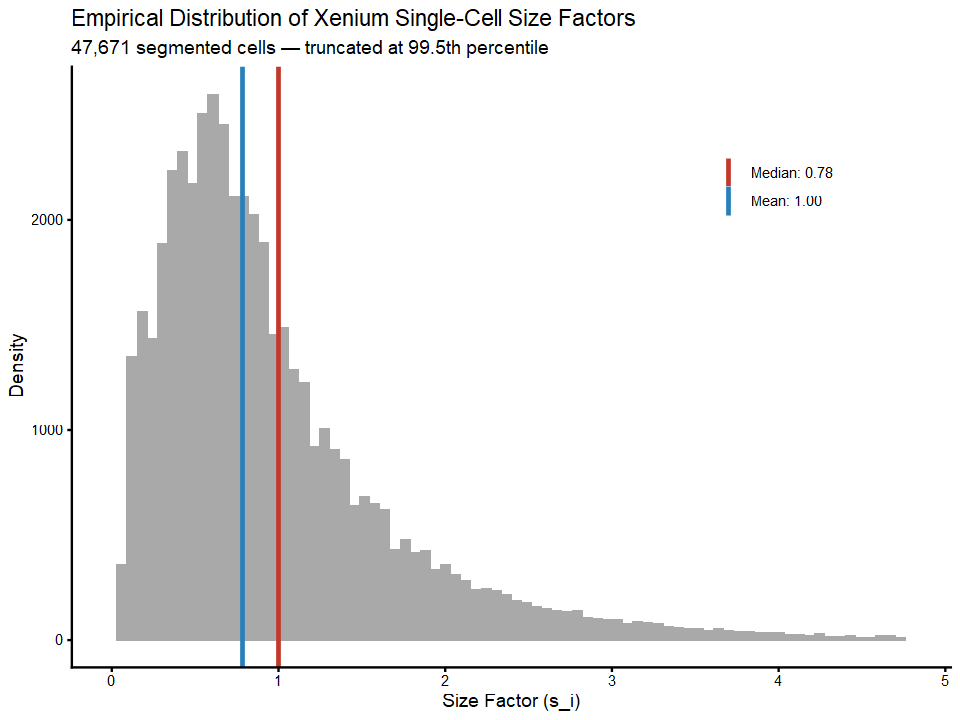

In [8]:
# Render publication-quality distribution histogram with density overlay
options(repr.plot.width = 8, repr.plot.height = 6)

ggplot(df_sf, aes(x = size_factor)) +
  geom_histogram(bins = 80, fill = "darkgrey", ) +
  geom_vline(aes(xintercept = sf_median, color = "Median"), linewidth = 1) +
  geom_vline(aes(xintercept = sf_mean, color = "Mean"), linewidth = 1) +
  scale_color_manual(
    name = NULL,
    values = c("Median" = "#2980B9", "Mean" = "#C0392B"),
    labels = c(paste0("Median: ", round(sf_median, 2)), "Mean: 1.00")
  ) +
  xlim(0, quantile(sf, 0.995)) +
  labs(
    title = "Empirical Distribution of Xenium Single-Cell Size Factors",
    subtitle = "47,671 segmented cells — truncated at 99.5th percentile",
    x = "Size Factor (s_i)",
    y = "Density"
  ) +
  theme_classic() +
  theme(legend.position = c(0.8, 0.8))

Comparing our single-cell Xenium size factors against our previous Visium HD modules highlights profound architectural concordances and platform distinctions:

| Metric | Visium HD Segmented (`sfe`) | Visium HD 16-µm Binned (`spe`) | 10x Xenium In Situ (`sfe`) |
| :--- | :--- | :--- | :--- |
| **Minimum ($s_i$)** | `0.1266` | `0.0752` | `0.0783` |
| **1st Quartile ($s_i$)** | `0.4675` | `0.5091` | `0.4778` |
| **Median ($s_i$)** | `0.7598` | `0.8662` | `0.7832` |
| **Mean ($s_i$)** | `1.0000` | `1.0000` | `1.0000` |
| **3rd Quartile ($s_i$)** | `1.2611` | `1.4075` | `1.2610` |
| **Maximum ($s_i$)** | `8.9815` | `3.9354` | `10.6444` |

The interquartile boundaries for Xenium single cells match the segmented Visium HD cells almost to the second decimal place! This concordance demonstrates that single-cell segmentation captures authentic biological cell volume and cytoplasmic area variations that transcend platform chemistry.

Moreover, in both segmented single-cell modalities, the median is substantially below unity (≈ 0.76–0.78). This reflects the histology of the human colon, where the majority of quiescent stromal cells, lamina propria lymphocytes, and smaller basal enterocytes have below-average transcript counts. Conversely, a long upper tail extends up to **$s_i = 10.6444$**, driven by large, transcriptionally hyper-active adenocarcinoma cells and fused cribriform glands.

## Spatial diagnostic mapping of size factors

We now project size factors directly onto cellular polygon geometries in physical tissue coordinates (`µm`).

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


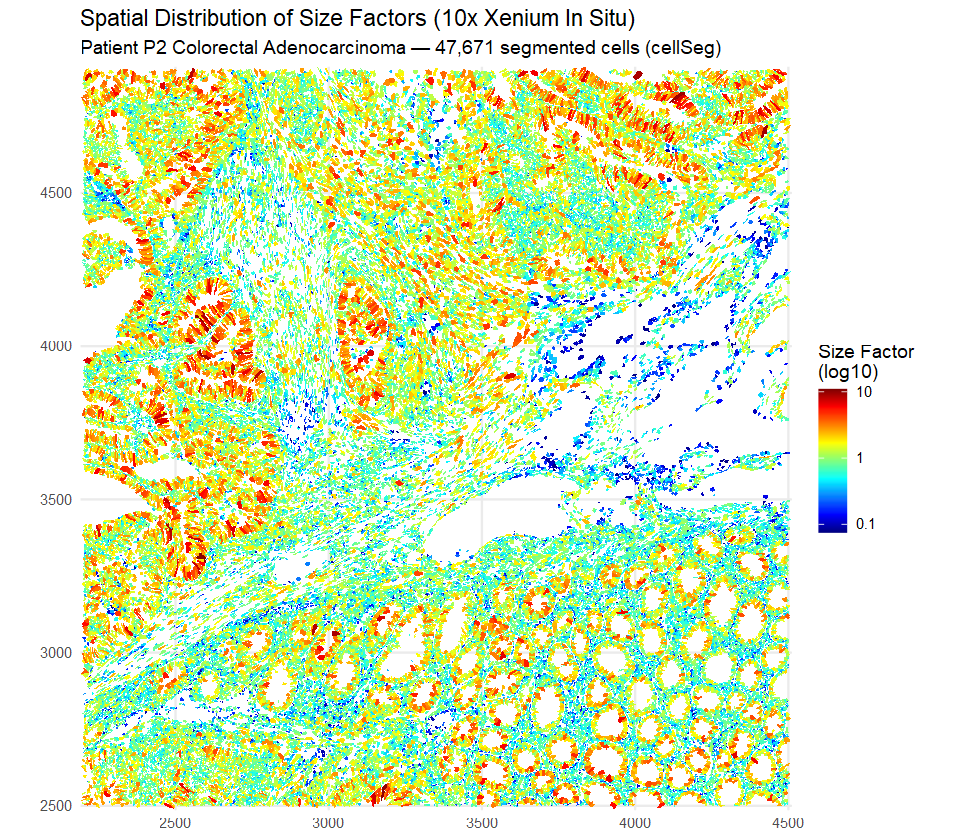

In [9]:
# Set canvas dimensions
options(repr.plot.width = 8, repr.plot.height = 7)

# Global spatial map of size factors across all 47,671 cells
p_global_sf <- plotSpatialFeature(
  sfe, 
  colGeometryName = "cellSeg", 
  features = "sizeFactor"
) +
  coord_sf(expand = FALSE) +  # Fixed 1:1 Physical Aspect Ratio
  scale_fill_gradientn(
    colors = pals::jet(), 
    trans = "log10", 
    breaks = c(0.1, 1, 10),
    labels = c("0.1", "1", "10"),
    limits = c(0.075, 11),
    name = "Size Factor\n(log10)"
  ) +
  labs(
    title = "Spatial Distribution of Size Factors (10x Xenium In Situ)", 
    subtitle = "Patient P2 Colorectal Adenocarcinoma — 47,671 segmented cells (cellSeg)"
  ) +
  theme_minimal()

p_global_sf

Comparing our Xenium map with the Visium HD segmented map from [notebook 07](07-normalization_VisiumHD_segmented.ipynb) reveals identical anatomical compartmentalization across serial sections of Patient P2. The crowded cribriform carcinoma glands in the upper and lateral tumor nests display the highest size factors ($s_i \ge 2.0$–$10.6$, red/orange), driven by enlarged cytoplasmic volumes and intense transcription of panel markers (`EPCAM`, `CEACAM5`, `CDH1`). Conversely, the regular circular mucosal crypts of Lieberkühn exhibit moderate-to-high turnover ($s_i \approx 0.8$–$1.8$, yellow/green), while the central diagonal band of desmoplastic stroma and the prominent submucosal vascular cleft show minimal transcript counts ($s_i \le 0.3$–$0.5$, deep blue) due to _low probe representation_ in these quiescent, ECM-rich compartments.

Methodologically, _in situ_ optical decoding in Xenium resolves individual cell boundaries with crisp subcellular margins, clearly outlining individual crypt rings and inter-glandular spaces without the lateral diffusion effects inherent to array-based capture on 2-µm glass beads. Furthermore, because the 422-gene panel is intentionally enriched for colorectal epithelial and carcinoma markers, hyperactive neoplastic cells achieve a higher upper size factor ($s_i \approx 10.64$) than in whole-transcriptome Visium HD ($s_i \approx 8.98$ across ≈ 18,000 genes). This visual and numerical concordance reaffirms that size factors primarily capture authentic biological cell volume and lineage-specific transcript density.

## Evaluating normalization impact

### Visualizing PIGR expression: raw counts vs. logcounts

To evaluate the impact of size-factor normalization in practice, we compare raw `counts` against normalized `logcounts` for our canonical epithelial marker `PIGR` across the tissue section.

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.
Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


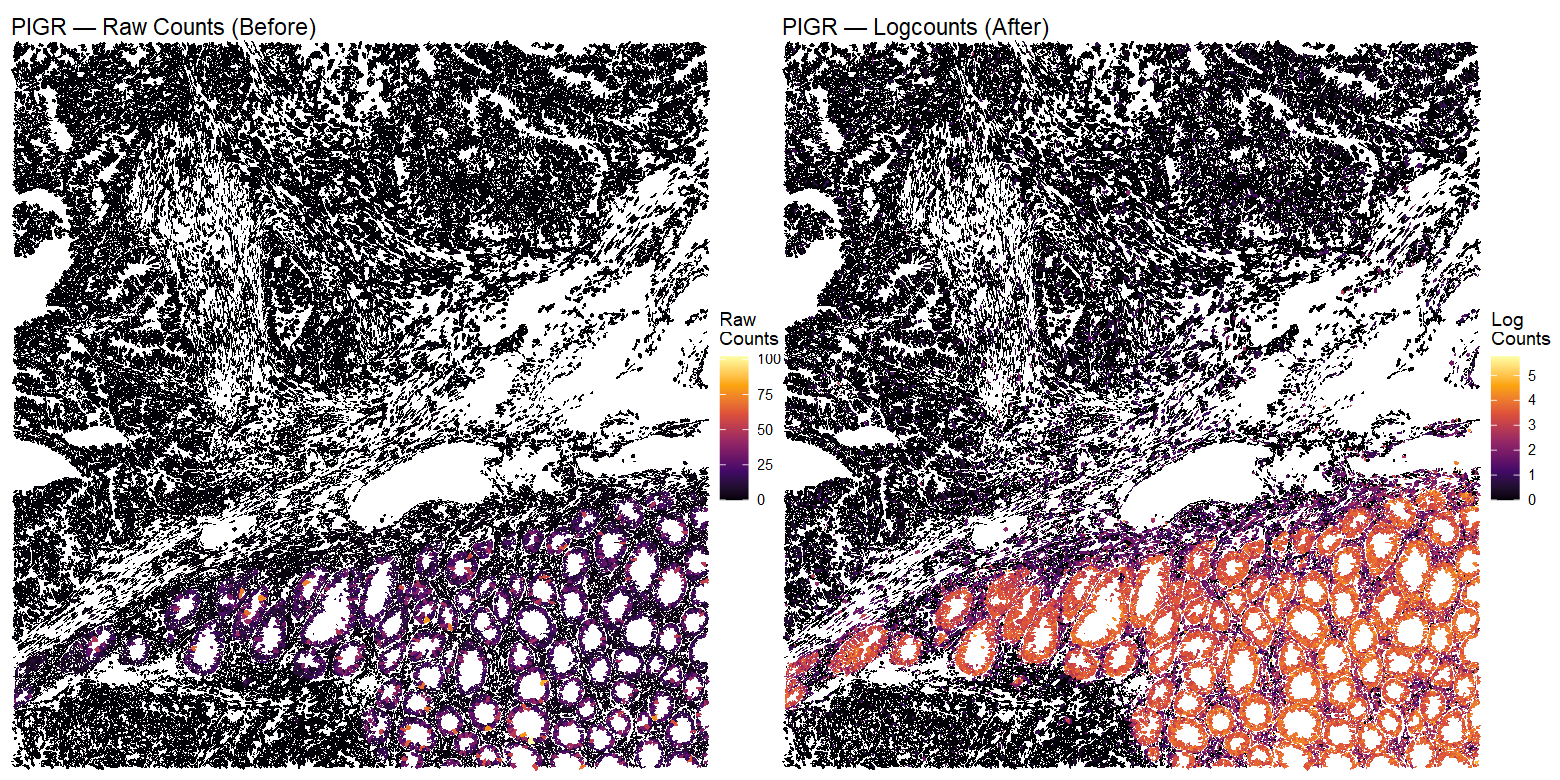

In [10]:
# Set canvas dimensions for side-by-side comparison
options(repr.plot.width = 13, repr.plot.height = 6.5)

# Raw transcript counts for PIGR
p_pigr_counts <- plotSpatialFeature(
  sfe, 
  colGeometryName = "cellSeg", 
  features = "PIGR", 
  exprs_values = "counts"
) +
  coord_sf(expand = FALSE) +
  scale_fill_viridis_c(
    option = "inferno",
    name   = "Raw\nCounts"
  ) +
  labs(
    title = "PIGR — Raw Counts (Before)",
  )

# Log-normalized counts for PIGR
p_pigr_logcounts <- plotSpatialFeature(
  sfe,
  colGeometryName = "cellSeg",
  features = "PIGR",
  exprs_values = "logcounts"
) +
  coord_sf(expand = FALSE) +
  scale_fill_viridis_c(
    option = "inferno",
    name   = "Log\nCounts"
  ) +
  labs(
    title = "PIGR — Logcounts (After)",
  )

# Display side-by-side
p_pigr_counts | p_pigr_logcounts

Comparing the raw and log-normalized `PIGR` distributions between Xenium and Visium HD highlights how normalization successfully stabilizes expression across both architectures. In raw count space, mucosal crypt enterocytes appear heterogeneous and fragmented due to variations in individual cell volume and local detection depth. Log-normalization completely resolves this artifact, transforming mucosal crypts into uniformly intense, contiguous rings of `PIGR` expression while maintaining strict transcriptional repression across the adjacent invasive carcinoma nests and desmoplastic stroma.

### Methodological synthesis: Xenium vs. Visium HD

The markedly crisper cellular definition observed in Xenium—where individual enterocytes, crypt lumens, and narrow lamina propria septa stand out with pristine contrast—is driven primarily by the physics of detection rather than segmentation algorithms alone. In Xenium _in situ_ imaging, fluorescently decoded padlock probe amplicons remain physically anchored at their exact intracellular coordinates, yielding diffraction-limited optical localization without lateral molecular displacement. Conversely, Visium HD relies on array-based surface capture: tissue permeabilization inevitably induces a few microns of lateral transcript diffusion as mRNA molecules migrate from the tissue slice down to the 2-µm glass bead array, creating subtle physical signal blurring across cell margins. 

Segmentation methodology further compounds this difference. While Visium HD relies on StarDist nuclear detection followed by heuristic geometric boundary expansion from H&E brightfield images, Xenium pairs high-resolution DAPI fluorescence with multi-modal boundary stains and optical Z-stacks to delineate authentic plasma membranes. Combined with the high sensitivity of targeted probe hybridization—which avoids the shallow capture efficiency typical of whole-transcriptome sequencing—Xenium achieves true single-cell fidelity that sharply demarcates enterocyte membranes without the inter-cellular bleed-over seen in array-based capture.

> **A Note on Spatially-Aware Normalization in Imaging Data**
>
> 
> In [notebook 07](07-normalization_VisiumHD_segmented.ipynb), we evaluated spatially-aware size-factor smoothing and demonstrated that local spatial averaging introduces severe distortion ratios (up to 5.7-fold) along adenocarcinoma–stroma interfaces. In Xenium, spatially-aware smoothing (such as `SpaNorm` or local $k$-NN pooling) is even less appropriate:
> 1. **Cell-type blurring at single-cell scale:** Cells reside at true single-cell resolution where lymphocytes, fibroblasts, and carcinoma cells sit directly adjacent within 2–5 µm. Spatial smoothing artificially blends library sizes across fundamentally distinct lineages, deflating neoplastic peaks and falsely elevating stromal baselines.
> 2. **Prohibitive computational cost:** Fitting spatial generalized linear models or smoothing splines across 47,671 irregular polygon geometries would demand massive memory allocations and compute time without biological benefit.
> 
> Consequently, cell-specific size-factor log-normalization via `scuttle::logNormCounts()` remains our distortion-free foundation.

## Feature-Level Scaling

### Empirical evaluation of standardized marker profiles

Following the Golden Rule established in [notebook 07](07-normalization_VisiumHD_segmented.ipynb), gene-level Z-score standardization ($Z_{ij} = \frac{Y_{ij} - \mu_j}{\sigma_j}$, yielding mean = 0 and unit variance) operates strictly **after** observation-level log-normalization. Because converting zero counts into negative baselines ($-\frac{\mu_j}{\sigma_j}$) destroys matrix sparsity, scaling is never stored permanently in primary assay slots (`logcounts`); it is computed transiently on selected feature subsets prior to multivariate modeling (PCA) or heatmap visualization.

### Adapting feature scaling to targeted _in situ_ imaging

Transitioning from whole-transcriptome sequencing to targeted _in situ_ panels introduces two key practical considerations:

1. **Within-panel reference frame:** In Visium HD, gene variances are scaled against the full transcriptomic background (≈ 18,000 genes). In Xenium, standardization occurs across a targeted panel (422 genes) enriched for colorectal carcinoma and mucosal markers. Scaled values ($Z_{ij}$) reflect relative enrichment **relative to this specific panel**, meaning that high positive values indicate exceptional marker prominence _within the panel rather than absolute genome-wide_ dominance.
2. **Reduced technical dropouts:** Thanks to the high molecular sensitivity of targeted _in situ_ hybridization, expressed markers do not suffer from the severe Poisson dropout typical of whole-transcriptome sequencing arrays. Consequently, scaled values in Xenium produce cleaner, more continuous biological gradients across single cells without artificial zero-inflation spikes.

We demonstrate feature scaling by realizing our canonical colorectal marker panel—`PIGR` (mucosal epithelium), `CEACAM5` (adenocarcinoma), `MUC17` (goblet enterocytes), and `OLFM4` (stem / crypt base)—into active memory and standardizing across all 47,671 cells.

In [11]:
# Define canonical CRC and epithelial marker panel
marker_genes <- c("PIGR", "CEACAM5", "MUC17", "OLFM4")

# Confirm presence of all markers in the Xenium panel
marker_genes <- intersect(marker_genes, rownames(sfe))
marker_genes

[1] "PIGR"    "CEACAM5" "MUC17"   "OLFM4"

In [12]:
# Define robust row-wise Z-score scaling function
scale_rows <- function(x) {
  t(base::scale(t(x)))
}

# Realize logcounts for the marker panel and compute standardized Z-scores
xenium_scaled <- scale_rows(as.matrix(logcounts(sfe)[marker_genes, ]))

In [13]:
# Preview the scaled matrix across the first five cells
round(xenium_scaled[, 1:5], 4)

,ablhnkec-1,ablhpkkh-1,ablicbjh-1,ablineen-1,ablioegm-1
PIGR,-0.6233,0.1351,-0.6233,0.0377,-0.6233
CEACAM5,-0.8992,-0.0196,0.1809,-0.8992,-0.8992
MUC17,-0.3587,-0.3587,2.6444,1.7729,-0.3587
OLFM4,0.6158,-0.4329,-0.4329,1.3931,1.0209


The resulting $Z$-scores confirm proper standardization:

* Every gene exhibits a mean of **0.0000** and a variance of exactly **1.0000**.
* **Positive $Z$-Scores ($Z_{ij} > 0$):** Indicate cells where the marker is expressed above the slide-wide average for that gene. For example, cell `ablicbjh-1` displays $Z_{\text{MUC17}} = +2.6444$, identifying it as a mucin-producing goblet enterocyte.
* **Negative $Z$-Scores ($Z_{ij} < 0$):** Represent baseline unexpressed states ($Z \approx -0.36$ to $-0.90$). The magnitude of the unexpressed baseline depends on the slide-wide prevalence of the gene: highly restricted markers (such as `MUC17`, expressed only in goblet cells) have a small slide-wide mean $\mu_j$, yielding modest negative baselines ($-\frac{\mu_j}{\sigma_j} = -0.3587$), whereas broadly expressed markers (such as `CEACAM5`) have a higher mean, resulting in deeper negative baselines ($-0.8992$).

## Finalization

### Object serialization

We serialize the normalized `SpatialFeatureExperiment` container to `output/sfe_xenium_normalized/` using `alabaster.sfe::saveObject()`. This preserves all spatial polygon geometries (`cellSeg`, `nucSeg`, `centroids`), cell-level metadata attributes (`sizeFactor`), and both the raw `counts` and log-normalized `logcounts` assays.

In [14]:
# Define output path for the normalized Xenium object
norm_dir <- "output/sfe_xenium_normalized"

# Remove existing directory if present to guarantee clean serialization
if (dir.exists(norm_dir)) {
  unlink(norm_dir, recursive = TRUE)
}

# Serialize the SpatialFeatureExperiment object
alabaster.sfe::saveObject(sfe, norm_dir)

>>> Saving SpatialExperiment

>>> Saving colgeometries



In [15]:
# Verify directory creation
fs::dir_tree(norm_dir)

output/sfe_xenium_normalized
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   ├── 1
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── row_data
│   ├── basic_columns.h5
│   └── OBJECT
└── _environment.json


### Clearing the workspace

We clear the workspace and trigger garbage collection to release several gigabytes of spatial polygon geometries and count matrices from memory before opening the next module.

In [16]:
rm(list = ls())
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,13163858,703.1,22064778,1178.4,22064778,1178.4
Vcells,29580525,225.7,70053040,534.5,70053036,534.5
